# Step 4a (Dolphin track) — Classifier head on top of Dolphin's detections

`Dolphin_Recall_Analysis.ipynb` showed Dolphin finds nearly all of our
labelled Table/Plot/Diagram/Figure_Mixed regions (recall close to 1 in
most classes, with a few partial-overlap cases still counted as found).
The remaining problem isn't detection -- it's that Dolphin also detects a
lot of things we don't want (headings, equations, sub-panels of a figure
we already caught as one box, running text, etc.).

So instead of fine-tuning a whole new detector, this notebook adds a small
**classifier head** on top: given the crop of one Dolphin-detected box,
predict whether it's one of our 4 wanted classes (and which one), or
Background. At inference time, Dolphin proposes the regions and this head
filters/labels them -- much cheaper than training a detector from scratch,
since Dolphin already did the hard part (finding *where* things are).

**Model**: a pretrained ResNet18 (ImageNet weights) with its final layer
replaced by a fresh `Linear` head for our 5 classes (Table/Plot/Diagram/
Figure_Mixed/Background). The backbone is frozen by default -- only the
new head trains -- since our labelled set is small (a few hundred crops
at most, drawn from ~10 papers); fine-tuning the whole backbone would
overfit fast. The loss is class-weighted, since Dolphin's Background boxes
heavily outnumber the classes we actually want.

**Before running this**: run `Dolphin_Inference.ipynb` (in
`../01_dolphin_baseline/`) first, so `dolphin_results/dolphin_flat.csv`
exists -- this notebook builds its training data from that file plus our
Labelbox ground truth.

**Folder layout this notebook expects:**
```
2026/
  My_code/
    step04_detection/
      01_dolphin_baseline/           <- dolphin_flat.csv lives here
      02_doclayout_yolo_finetune/
      03_dolphin_classifier_head/    <- this notebook lives here
  Pre-Pages-2Annotate/                 <- ndjson export + topic image folders
```

**Compute note**: `EPOCHS`/`PRETRAINED` below default to a quick,
network-free smoke test (random-init backbone, 2 epochs) so the pipeline
can be checked without a real download. For a real run, set
`PRETRAINED = True` (downloads ImageNet weights once) and raise `EPOCHS`
to something like 20-40 -- with a frozen backbone this trains fast even
on CPU/MPS.


In [1]:
# Locate the project from either the project root or a notebook directory.
import os
import sys
from pathlib import Path
PROJECT_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
                    if (p / "Pre-Pages-2Annotate").is_dir())
sys.path.insert(0, str(PROJECT_ROOT / "My_code"))
from annotation_inputs import latest_annotation_export, annotated_image_paths, build_image_index
os.chdir(PROJECT_ROOT / 'My_code/step04_detection/02_dolphin_classifier_head')
%matplotlib inline
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd()))
import step04a_build_classifier_dataset as build_ds
import step04a_train_dolphin_classifier as train_clf

ANNOTATIONS_ROOT = PROJECT_ROOT / "Pre-Pages-2Annotate" / "Exported_annotated_data"
NDJSON_PATH = latest_annotation_export(ANNOTATIONS_ROOT)
print(f"Annotation export: {NDJSON_PATH.name}")
IMAGES_ROOT = Path("../../../Pre-Pages-2Annotate")
DOLPHIN_CSV = Path("../01_dolphin_baseline/dolphin_results/dolphin_flat.csv")
DATASET_ROOT = Path("./classifier_dataset")

assert NDJSON_PATH.exists(), f"Export not found at {NDJSON_PATH.resolve()}"
assert IMAGES_ROOT.exists(), f"Images root not found at {IMAGES_ROOT.resolve()}"
assert DOLPHIN_CSV.exists(), (
    f"{DOLPHIN_CSV.resolve()} not found -- run Dolphin_Inference.ipynb first."
)
print("Paths OK.")


Annotation export: Export  project - STEPS-Paper-Annotation - 9_23_2026.ndjson
Paths OK.


## Step 1 — Build the labelled crop dataset

Every Dolphin-detected box gets labelled with whichever ground-truth class
best overlaps it (or Background if none does), then gets cropped out of
the page image. Split by **paper**, not page, same reasoning as the YOLO
dataset -- so validation reflects generalization to a paper Dolphin's
never seen labelled boxes for.


In [2]:
stats = build_ds.build_classifier_dataset(
    ndjson_path=NDJSON_PATH,
    images_root=IMAGES_ROOT,
    dolphin_csv_path=DOLPHIN_CSV,
    output_root=DATASET_ROOT,
    val_fraction=0.15,
)


──────────────────────────────────────────────────────
Pages with Dolphin detections matched against ground truth: 267
Classes: ['Background', 'Diagram', 'Figure_Mixed', 'Plot', 'Table']

Train crops:
  Background     4186
  Diagram        104
  Figure_Mixed   25
  Plot           119
  Table          145

Val crops:
  Background     638
  Diagram        12
  Figure_Mixed   8
  Plot           28
  Table          25

[Note] Background crops (4824) heavily outnumber wanted-class crops (466), as expected since Dolphin also boxes headings/equations/etc. The training script class-weights the loss for this by default.

Written to: /Users/md_halim_mondol/Desktop/STEPS-LLM/2026/My_code/step04_detection/02_dolphin_classifier_head/classifier_dataset/
  train/<class>/*.png, val/<class>/*.png   (ImageFolder-ready)
  manifest.csv                              every detection + its assigned label


## Preview a few crops per class

A quick sanity check that the labelling logic is grabbing the right pixels.

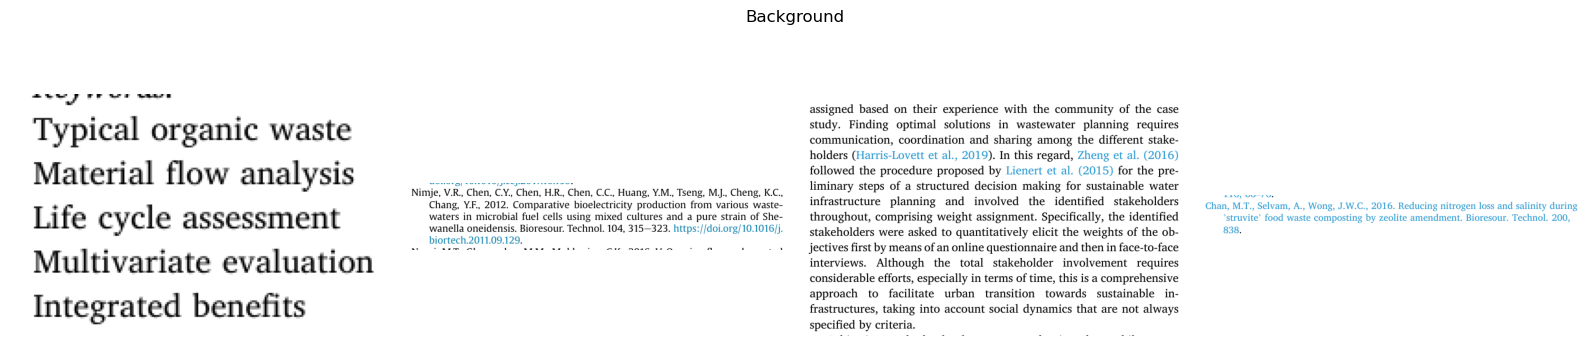

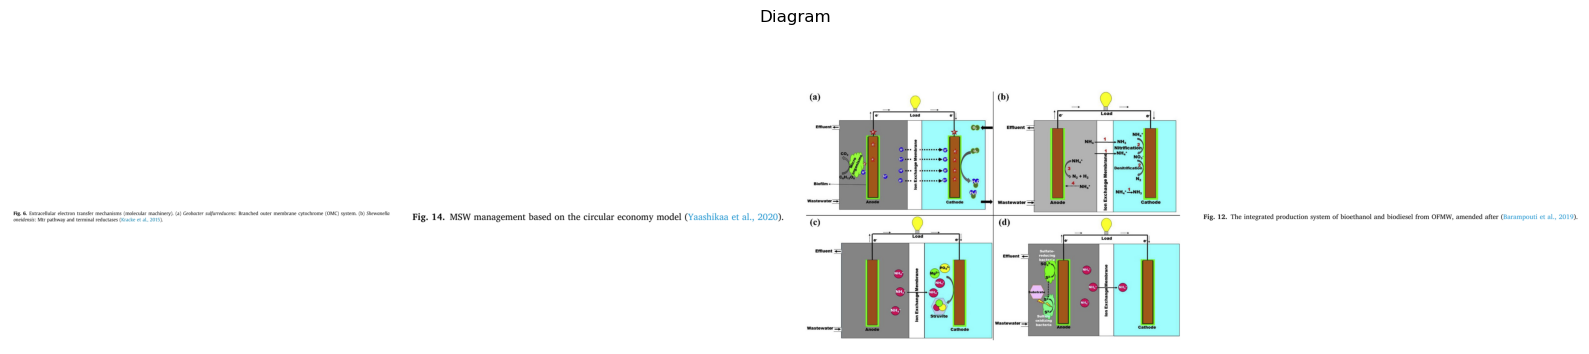

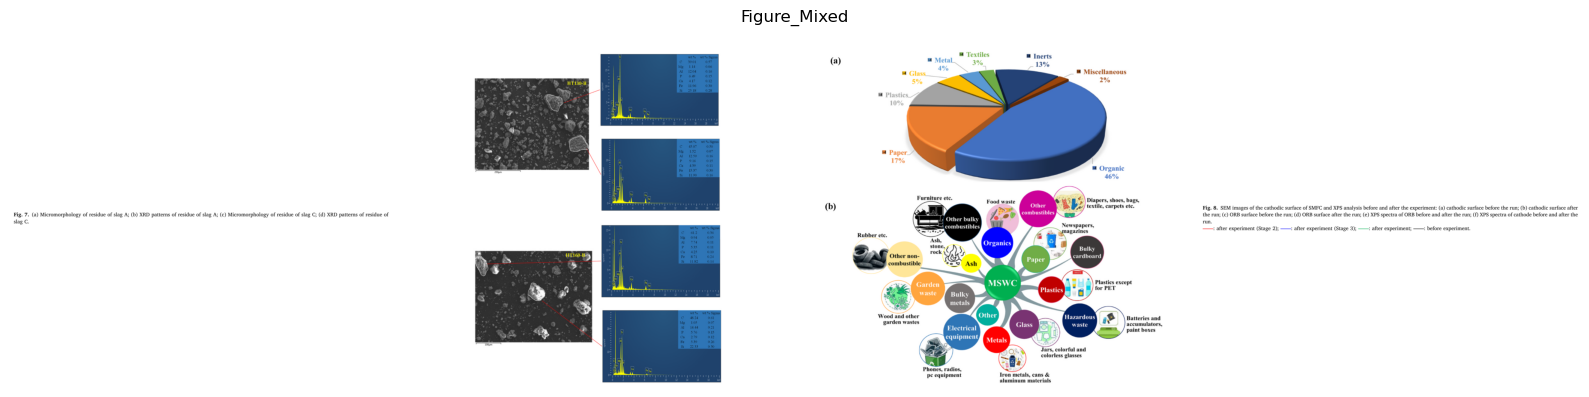

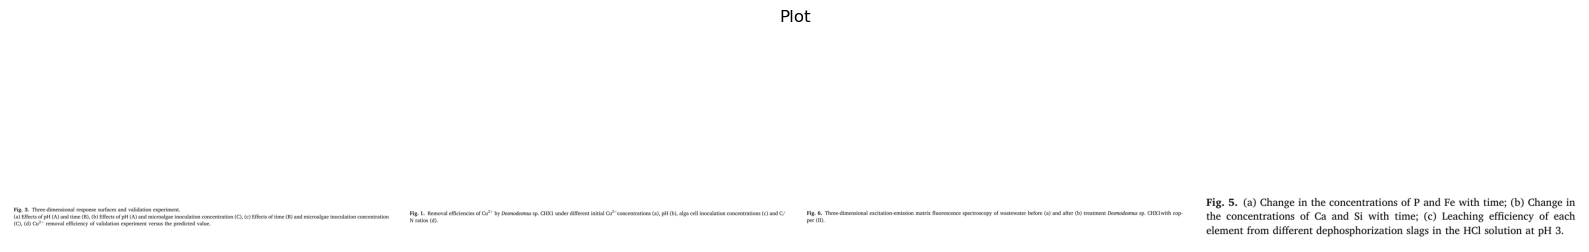

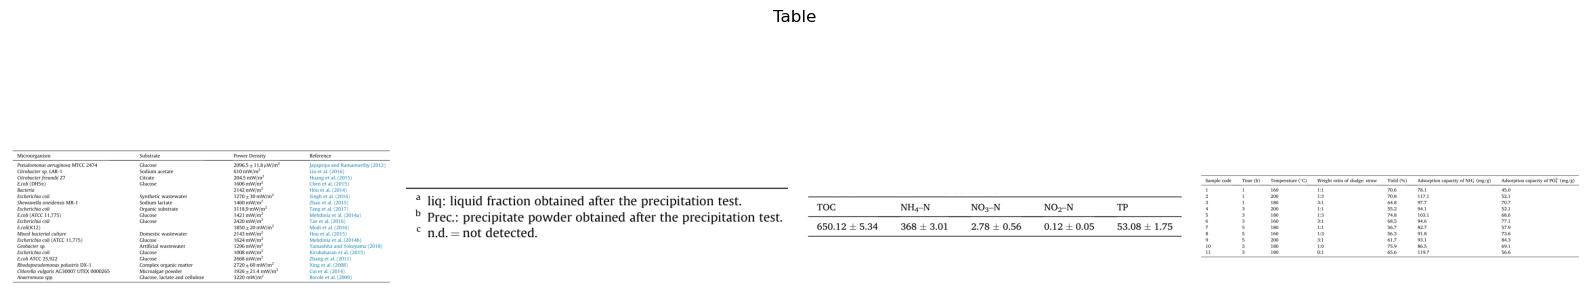

In [3]:
import random
from PIL import Image
import matplotlib.pyplot as plt

for class_name in stats["classes"]:
    class_dir = DATASET_ROOT / "train" / class_name
    files = sorted(class_dir.glob("*.png")) or sorted((DATASET_ROOT / "val" / class_name).glob("*.png"))
    if not files:
        print(f"(no crops at all for '{class_name}')")
        continue
    sample = random.sample(files, min(4, len(files)))
    fig, axes = plt.subplots(1, len(sample), figsize=(4 * len(sample), 4))
    if len(sample) == 1:
        axes = [axes]
    for ax, fpath in zip(axes, sample):
        ax.imshow(Image.open(fpath))
        ax.axis("off")
    fig.suptitle(class_name)
    plt.tight_layout()
    plt.show()


## Step 2 — Train the classifier head

`PRETRAINED = False` below keeps this a network-free smoke test (random
backbone weights) so the pipeline can be validated without a download.
Flip it to `True` for a real run -- downloads ImageNet ResNet18 weights
once, then trains just the new head on top.


In [4]:
BACKBONE = "resnet18"
PRETRAINED = True      # <-- set True for a real run (downloads ImageNet weights once)
FREEZE_BACKBONE = True  # <-- keep True until there's a lot more labelled data
EPOCHS = 50               # <-- raise to ~20-40 for a real run
IMAGE_SIZE = 224 #96 if not PRETRAINED else 224  # smaller is fine for a from-scratch smoke test

model, result = train_clf.train_classifier_head(
    data=DATASET_ROOT,
    backbone=BACKBONE,
    pretrained=PRETRAINED,
    freeze_backbone=FREEZE_BACKBONE,
    epochs=EPOCHS,
    image_size=IMAGE_SIZE,
)


Device: mps  |  Backbone: resnet18 (pretrained=True, frozen=True)  |  Classes: ['Background', 'Diagram', 'Figure_Mixed', 'Plot', 'Table']
Trainable params: 2,565 / 11,179,077
Epoch   1/50  train_loss=1.2217 train_acc=0.829  val_loss=0.5029 val_acc=0.861
Epoch   2/50  train_loss=0.8625 train_acc=0.884  val_loss=0.5874 val_acc=0.809
Epoch   3/50  train_loss=0.7113 train_acc=0.908  val_loss=0.5378 val_acc=0.850
Epoch   4/50  train_loss=0.6558 train_acc=0.907  val_loss=0.2942 val_acc=0.916
Epoch   5/50  train_loss=0.6062 train_acc=0.912  val_loss=0.3925 val_acc=0.883
Epoch   6/50  train_loss=0.5653 train_acc=0.917  val_loss=0.3130 val_acc=0.910
Epoch   7/50  train_loss=0.5933 train_acc=0.915  val_loss=0.6734 val_acc=0.785
Epoch   8/50  train_loss=0.5076 train_acc=0.918  val_loss=0.3130 val_acc=0.909
Epoch   9/50  train_loss=0.4600 train_acc=0.931  val_loss=0.2537 val_acc=0.924
Epoch  10/50  train_loss=0.4970 train_acc=0.919  val_loss=0.1727 val_acc=0.952
Epoch  11/50  train_loss=0.4586 tra

## Step 3 — Training curves

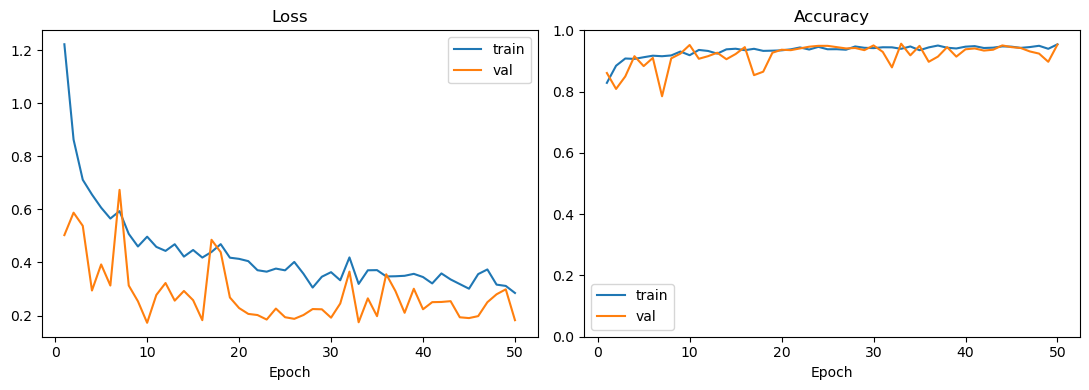

In [5]:
import pandas as pd

history_df = pd.DataFrame(result["history"])

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(history_df["epoch"], history_df["train_loss"], label="train")
axes[0].plot(history_df["epoch"], history_df["val_loss"], label="val")
axes[0].set(title="Loss", xlabel="Epoch")
axes[0].legend()

axes[1].plot(history_df["epoch"], history_df["train_acc"], label="train")
axes[1].plot(history_df["epoch"], history_df["val_acc"], label="val")
axes[1].set(title="Accuracy", xlabel="Epoch", ylim=(0, 1))
axes[1].legend()

plt.tight_layout()
plt.show()


## Step 4 — Confusion matrix on the held-out papers

The number to watch isn't overall accuracy (Background dominates the raw
count) -- it's how often a wanted class (Table/Plot/Diagram/Figure_Mixed)
gets confused with Background or with each other, since that's exactly
what this head is meant to prevent downstream.


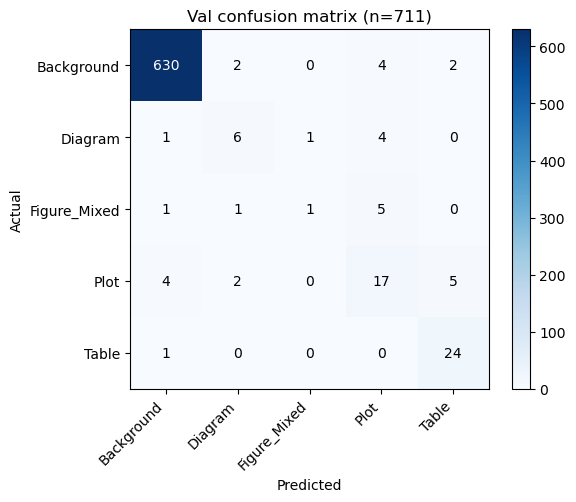

Per-class val recall (of the boxes actually in this class, how many did we get right):
  Background     630/638  (98.7%)
  Diagram        6/12  (50.0%)
  Figure_Mixed   1/8  (12.5%)
  Plot           17/28  (60.7%)
  Table          24/25  (96.0%)


In [6]:
import numpy as np

classes = result["classes"]
confusion = np.array(result["final_val"]["confusion"])

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(confusion, cmap="Blues")
ax.set_xticks(range(len(classes))); ax.set_xticklabels(classes, rotation=45, ha="right")
ax.set_yticks(range(len(classes))); ax.set_yticklabels(classes)
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
for i in range(len(classes)):
    for j in range(len(classes)):
        ax.text(j, i, confusion[i, j], ha="center", va="center",
                color="white" if confusion[i, j] > confusion.max() / 2 else "black")
ax.set_title(f"Val confusion matrix (n={result['final_val']['n']})")
plt.colorbar(im)
plt.tight_layout()
plt.show()

print("Per-class val recall (of the boxes actually in this class, how many did we get right):")
for i, c in enumerate(classes):
    total = confusion[i].sum()
    correct = confusion[i, i]
    print(f"  {c:<14} {correct}/{total}" + (f"  ({correct/total:.1%})" if total else "  (no val examples)"))


## Step 5 — See it filter a real page

Runs the trained head on every Dolphin detection for one val-split page,
and shows Dolphin's raw (unfiltered) boxes next to only the boxes the
classifier head kept -- i.e. what actually reaches the downstream
extraction step once this filter is in place.


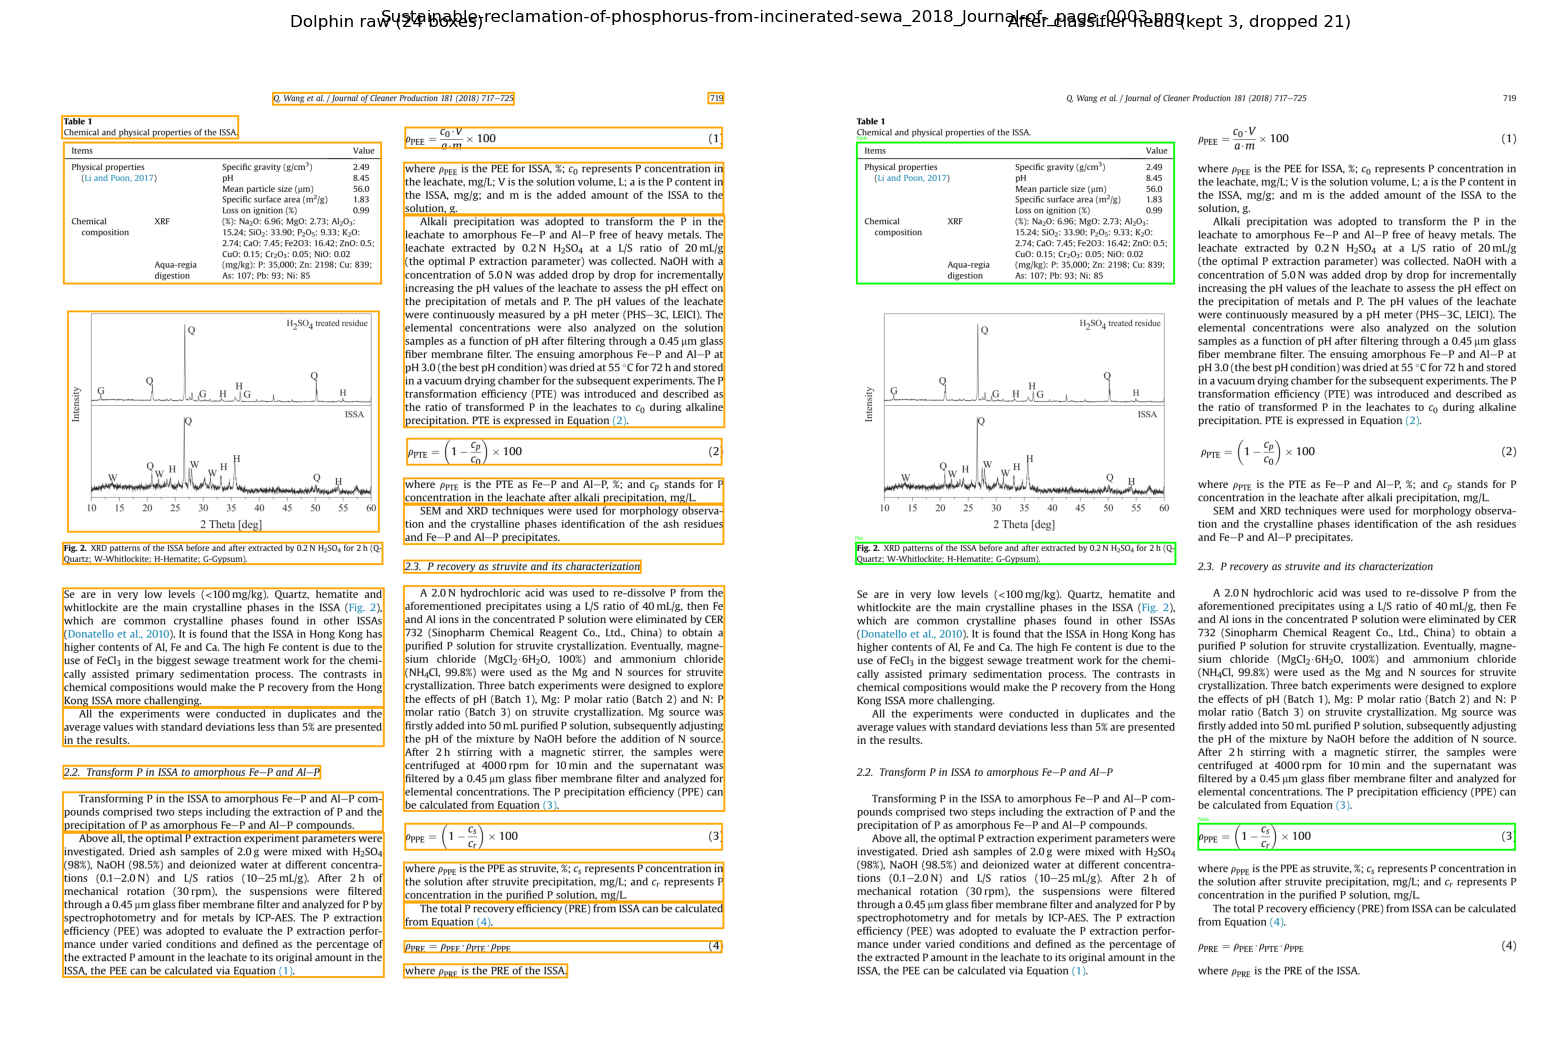

In [7]:
import torch
from torchvision import transforms
from PIL import ImageDraw

IMAGENET_MEAN, IMAGENET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
infer_tf = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

sys.path.insert(0, str(Path("../01_dolphin_baseline").resolve()))
from step04a_measure_dolphin_recall import load_dolphin_detections

detections_by_image = load_dolphin_detections(DOLPHIN_CSV)
val_pages_with_dets = [
    p for p in stats.get("val_papers", [])
]
# fall back to any page with detections if val_papers metadata isn't handy
candidate_images = [img for img in detections_by_image if any(
    img.split("_page_")[0] == paper for paper in stats["val_papers"]
)] or list(detections_by_image.keys())

demo_image_name = random.choice(candidate_images)
demo_boxes = detections_by_image[demo_image_name]

# find the local page image the same way step04a's collect_pages does
demo_path = next((f for f in IMAGES_ROOT.rglob(demo_image_name)), None)
assert demo_path is not None, f"Couldn't find local image for {demo_image_name}"

model.eval()
img = Image.open(demo_path).convert("RGB")
img_raw = img.copy()
img_filtered = img.copy()
draw_raw = ImageDraw.Draw(img_raw)
draw_filtered = ImageDraw.Draw(img_filtered)

kept, dropped = 0, 0
for d in demo_boxes:
    left, top, width, height = d["box"]
    draw_raw.rectangle([left, top, left + width, top + height], outline="orange", width=4)

    crop = img.crop((max(0, left), max(0, top), left + width, top + height))
    if crop.size[0] < 2 or crop.size[1] < 2:
        continue
    with torch.no_grad():
        logits = model(infer_tf(crop).unsqueeze(0).to(result["device"]))
        pred_class = classes[logits.argmax(dim=1).item()]

    if pred_class != "Background":
        draw_filtered.rectangle([left, top, left + width, top + height], outline="lime", width=4)
        draw_filtered.text((left, max(0, top - 14)), pred_class, fill="lime")
        kept += 1
    else:
        dropped += 1

fig, axes = plt.subplots(1, 2, figsize=(16, 16 * img.size[1] / img.size[0] / 2))
axes[0].imshow(img_raw); axes[0].axis("off")
axes[0].set_title(f"Dolphin raw ({len(demo_boxes)} boxes)")
axes[1].imshow(img_filtered); axes[1].axis("off")
axes[1].set_title(f"After classifier head (kept {kept}, dropped {dropped})")
plt.suptitle(demo_image_name)
plt.tight_layout()
plt.show()


## Save the trained head

Saves just the model weights (+ the class list, needed to map predicted
indices back to names) -- small enough to keep in the repo and reload
later without retraining.


In [8]:
CHECKPOINT_PATH = Path("./dolphin_classifier_head.pt")
torch.save({"state_dict": model.state_dict(), "classes": classes,
            "backbone": BACKBONE, "image_size": IMAGE_SIZE}, CHECKPOINT_PATH)
print(f"Saved to {CHECKPOINT_PATH.resolve()}")


Saved to /Users/md_halim_mondol/Desktop/STEPS-LLM/2026/My_code/step04_detection/02_dolphin_classifier_head/dolphin_classifier_head.pt
